Student Dropout and Academic Success Classification

In [2]:
# Check the current folder and the files in it
from pathlib import Path

project_folder = Path.cwd()
print("Project folder:", project_folder)
print("Files:", [file.name for file in project_folder.iterdir()])

Project folder: C:\Users\aalex\ML_Assignment2
Files: ['.ipynb_checkpoints', 'data.csv', 'ML_Assignment2.ipynb']


In [3]:
import pandas as pd

data = pd.read_csv("data.csv", sep=";")

print("Dataset shape:", data.shape)
print(data.head())

Dataset shape: (4424, 37)
   Marital status  Application mode  Application order  Course  \
0               1                17                  5     171   
1               1                15                  1    9254   
2               1                 1                  5    9070   
3               1                17                  2    9773   
4               2                39                  1    8014   

   Daytime/evening attendance\t  Previous qualification  \
0                             1                       1   
1                             1                       1   
2                             1                       1   
3                             1                       1   
4                             0                       1   

   Previous qualification (grade)  Nacionality  Mother's qualification  \
0                           122.0            1                      19   
1                           160.0            1                       1   


In [4]:
print("Column names:")
print(data.columns.tolist())

print("\nData types:")
print(data.dtypes)

print("\nMissing values per column:")
print(data.isnull().sum())

print("\nTarget class counts:")
print(data["Target"].value_counts())

Column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target

In [6]:
# Import the function used to split data into training and test sets
from sklearn.model_selection import train_test_split

# Create X by keeping all feature columns and removing the target column
X = data.drop(columns=["Target"])

# Create y using the target column that the models will learn to predict
y = data["Target"]

# Split the data into training and test portions
# Keep 20 percent of the rows for testing
# Use a fixed random seed so the split is repeatable
# Preserve the target class proportions in both portions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the number of rows and columns in the training features
print("Training features:", X_train.shape)

# Display the number of rows and columns in the test features
print("Test features:", X_test.shape)

# Show the proportion of each target class in the training set
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True))

# Show the proportion of each target class in the test set
print("\nTest target proportions:")
print(y_test.value_counts(normalize=True))

Training features: (3539, 36)
Test features: (885, 36)

Training target proportions:
Target
Graduate    0.499294
Dropout     0.321277
Enrolled    0.179429
Name: proportion, dtype: float64

Test target proportions:
Target
Graduate    0.499435
Dropout     0.320904
Enrolled    0.179661
Name: proportion, dtype: float64


Now lets start with the Logistic Regression

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Build a pipeline that scales features before fitting Logistic Regression
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Train the model using only the training data
logistic_model.fit(X_train, y_train)

# Predict the target classes for the test data
logistic_predictions = logistic_model.predict(X_test)

# Calculate the fraction of test predictions that are correct
logistic_accuracy = accuracy_score(y_test, logistic_predictions)

# Display the accuracy
print("Logistic Regression accuracy:", logistic_accuracy)

Logistic Regression accuracy: 0.768361581920904


Now lets see accuracy of Decision Tree. It doesn’t need feature scaling

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Create a decision tree classifier with a fixed random seed
tree_model = DecisionTreeClassifier(random_state=42)

# Train the tree using the training data
tree_model.fit(X_train, y_train)

# Predict target classes for the test data
tree_predictions = tree_model.predict(X_test)

# Calculate the fraction of test predictions that are correct
tree_accuracy = accuracy_score(y_test, tree_predictions)

# Display the accuracy
print("Decision Tree accuracy:", tree_accuracy)

Decision Tree accuracy: 0.6971751412429379


Lets check K-Nearest Neighbors (KNN). KNN compares distances between examples

In [9]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Scale the features, then create a KNN classifier using 5 neighbors
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# Train KNN with the training data
knn_model.fit(X_train, y_train)

# Predict the target classes for the test data
knn_predictions = knn_model.predict(X_test)

# Calculate the fraction of test predictions that are correct
knn_accuracy = accuracy_score(y_test, knn_predictions)

# Display the accuracy
print("KNN accuracy:", knn_accuracy)

KNN accuracy: 0.6677966101694915


Gaussian Naive Bayes. It doesn’t require feature scaling

In [10]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

# Create a Gaussian Naive Bayes classifier
naive_bayes_model = GaussianNB()

# Train the classifier using the training data
naive_bayes_model.fit(X_train, y_train)

# Predict target classes for the test data
naive_bayes_predictions = naive_bayes_model.predict(X_test)

# Calculate the fraction of test predictions that are correct
naive_bayes_accuracy = accuracy_score(y_test, naive_bayes_predictions)

# Display the accuracy
print("Naive Bayes accuracy:", naive_bayes_accuracy)

Naive Bayes accuracy: 0.6598870056497175


Support Vector Machine (SVM). We’ll scale its features, and enable probability estimates so we can calculate AUC later.

In [12]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score

# Put scaling and the SVM together in a pipeline
scaled_svm = make_pipeline(
    StandardScaler(),
    SVC(random_state=42)
)

# Calibrate the SVM so it can provide class probabilities for AUC
svm_model = CalibratedClassifierCV(
    estimator=scaled_svm,
    ensemble=False
)

# Train the calibrated SVM on the training data
svm_model.fit(X_train, y_train)

# Predict target classes for the test data
svm_predictions = svm_model.predict(X_test)

# Calculate the fraction of test predictions that are correct
svm_accuracy = accuracy_score(y_test, svm_predictions)

# Display the accuracy
print("Support Vector Machine accuracy:", svm_accuracy)

Support Vector Machine accuracy: 0.7593220338983051


The updated SVM achieved 75.9% accuracy, close to Logistic Regression at 76.8%. So far, Logistic Regression is highest on accuracy, though we’ll compare all six required metrics before drawing conclusions.

Lets check other metric for Logistic regression

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
)

# Calculate the predicted class probabilities for the test rows
logistic_probabilities = logistic_model.predict_proba(X_test)

# Calculate the macro-averaged multiclass AUC
from sklearn.metrics import roc_auc_score
logistic_auc = roc_auc_score(
    y_test,
    logistic_probabilities,
    multi_class="ovr",
    average="macro"
)

# Calculate the required classification metrics
logistic_precision = precision_score(
    y_test, logistic_predictions, average="macro"
)
logistic_recall = recall_score(
    y_test, logistic_predictions, average="macro"
)
logistic_f1 = f1_score(
    y_test, logistic_predictions, average="macro"
)
logistic_mcc = matthews_corrcoef(y_test, logistic_predictions)

# Display the metrics
print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print("AUC:", logistic_auc)
print("Precision:", logistic_precision)
print("Recall:", logistic_recall)
print("F1:", logistic_f1)
print("MCC:", logistic_mcc)

Accuracy: 0.768361581920904
AUC: 0.877812197594502
Precision: 0.7070053645836096
Recall: 0.6754261112173291
F1: 0.682601247658837
MCC: 0.6150140447373827


Lets check other metric for DecisionTree

In [14]:
from sklearn.metrics import roc_auc_score

# Predict class probabilities for the test rows
tree_probabilities = tree_model.predict_proba(X_test)

# Calculate macro-averaged multiclass AUC using one-vs-rest
tree_auc = roc_auc_score(
    y_test,
    tree_probabilities,
    multi_class="ovr",
    average="macro"
)

# Calculate macro-averaged precision
tree_precision = precision_score(
    y_test, tree_predictions, average="macro"
)

# Calculate macro-averaged recall
tree_recall = recall_score(
    y_test, tree_predictions, average="macro"
)

# Calculate macro-averaged F1 score
tree_f1 = f1_score(
    y_test, tree_predictions, average="macro"
)

# Calculate Matthews correlation coefficient
tree_mcc = matthews_corrcoef(y_test, tree_predictions)

# Display the Decision Tree metrics
print("Accuracy:", accuracy_score(y_test, tree_predictions))
print("AUC:", tree_auc)
print("Precision:", tree_precision)
print("Recall:", tree_recall)
print("F1:", tree_f1)
print("MCC:", tree_mcc)

Accuracy: 0.6971751412429379
AUC: 0.742169292663399
Precision: 0.6377940316294123
Recall: 0.6396579005417385
F1: 0.6385428929827607
MCC: 0.5106372902135513


KNN-finding other metrics

In [15]:
# Predict class probabilities for the test rows
knn_probabilities = knn_model.predict_proba(X_test)

# Calculate macro-averaged multiclass AUC using one-vs-rest
knn_auc = roc_auc_score(
    y_test,
    knn_probabilities,
    multi_class="ovr",
    average="macro"
)

# Calculate macro-averaged precision
knn_precision = precision_score(
    y_test, knn_predictions, average="macro"
)

# Calculate macro-averaged recall
knn_recall = recall_score(
    y_test, knn_predictions, average="macro"
)

# Calculate macro-averaged F1 score
knn_f1 = f1_score(
    y_test, knn_predictions, average="macro"
)

# Calculate Matthews correlation coefficient
knn_mcc = matthews_corrcoef(y_test, knn_predictions)

# Display the KNN metrics
print("Accuracy:", accuracy_score(y_test, knn_predictions))
print("AUC:", knn_auc)
print("Precision:", knn_precision)
print("Recall:", knn_recall)
print("F1:", knn_f1)
print("MCC:", knn_mcc)

Accuracy: 0.6677966101694915
AUC: 0.7815521556448474
Precision: 0.5801543298710523
Recall: 0.5718948904064034
F1: 0.5730145507444867
MCC: 0.4464833149015487


metrics for Gaussian Naive Bayes

In [16]:
# Predict class probabilities for the test rows
naive_bayes_probabilities = naive_bayes_model.predict_proba(X_test)

# Calculate macro-averaged multiclass AUC using one-vs-rest
naive_bayes_auc = roc_auc_score(
    y_test,
    naive_bayes_probabilities,
    multi_class="ovr",
    average="macro"
)

# Calculate macro-averaged precision
naive_bayes_precision = precision_score(
    y_test, naive_bayes_predictions, average="macro"
)

# Calculate macro-averaged recall
naive_bayes_recall = recall_score(
    y_test, naive_bayes_predictions, average="macro"
)

# Calculate macro-averaged F1 score
naive_bayes_f1 = f1_score(
    y_test, naive_bayes_predictions, average="macro"
)

# Calculate Matthews correlation coefficient
naive_bayes_mcc = matthews_corrcoef(
    y_test, naive_bayes_predictions
)

# Display the Naive Bayes metrics
print("Accuracy:", accuracy_score(y_test, naive_bayes_predictions))
print("AUC:", naive_bayes_auc)
print("Precision:", naive_bayes_precision)
print("Recall:", naive_bayes_recall)
print("F1:", naive_bayes_f1)
print("MCC:", naive_bayes_mcc)

Accuracy: 0.6598870056497175
AUC: 0.7907612487893263
Precision: 0.5668573919901769
Recall: 0.5586457311653104
F1: 0.5581421462862765
MCC: 0.43030786975102214


metrics for the Support Vector Machine

In [17]:
# Predict class probabilities for the test rows
svm_probabilities = svm_model.predict_proba(X_test)

# Calculate macro-averaged multiclass AUC using one-vs-rest
svm_auc = roc_auc_score(
    y_test,
    svm_probabilities,
    multi_class="ovr",
    average="macro"
)

# Calculate macro-averaged precision
svm_precision = precision_score(
    y_test, svm_predictions, average="macro"
)

# Calculate macro-averaged recall
svm_recall = recall_score(
    y_test, svm_predictions, average="macro"
)

# Calculate macro-averaged F1 score
svm_f1 = f1_score(
    y_test, svm_predictions, average="macro"
)

# Calculate Matthews correlation coefficient
svm_mcc = matthews_corrcoef(y_test, svm_predictions)

# Display the Support Vector Machine metrics
print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("AUC:", svm_auc)
print("Precision:", svm_precision)
print("Recall:", svm_recall)
print("F1:", svm_f1)
print("MCC:", svm_mcc)

Accuracy: 0.7593220338983051
AUC: 0.8405482667771503
Precision: 0.7059726818346231
Recall: 0.6678818941328517
F1: 0.67856720582808
MCC: 0.6002467371155686


Now let’s put the results into the comparison table

In [18]:
# Create a table to compare the five classifiers
results = pd.DataFrame({
    "ML Model Name": [
        "Logistic Regression",
        "Decision Tree",
        "KNN",
        "Naive Bayes",
        "Support Vector Machine"
    ],
    "Accuracy": [
        logistic_accuracy,
        tree_accuracy,
        knn_accuracy,
        naive_bayes_accuracy,
        svm_accuracy
    ],
    "AUC": [
        logistic_auc,
        tree_auc,
        knn_auc,
        naive_bayes_auc,
        svm_auc
    ],
    "Precision": [
        logistic_precision,
        tree_precision,
        knn_precision,
        naive_bayes_precision,
        svm_precision
    ],
    "Recall": [
        logistic_recall,
        tree_recall,
        knn_recall,
        naive_bayes_recall,
        svm_recall
    ],
    "F1": [
        logistic_f1,
        tree_f1,
        knn_f1,
        naive_bayes_f1,
        svm_f1
    ],
    "MCC": [
        logistic_mcc,
        tree_mcc,
        knn_mcc,
        naive_bayes_mcc,
        svm_mcc
    ]
})

# Round the displayed metric values to three decimal places
results.round(3)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.768,0.878,0.707,0.675,0.683,0.615
1,Decision Tree,0.697,0.742,0.638,0.640,0.639,0.511
2,KNN,0.668,0.782,0.580,0.572,0.573,0.446
3,Naive Bayes,0.660,0.791,0.567,0.559,0.558,0.430
4,Support Vector Machine,0.759,0.841,0.706,0.668,0.679,0.600


In [19]:
# Display the comparison table without the extra row index
print(results.round(3).to_string(index=False))

         ML Model Name  Accuracy   AUC  Precision  Recall    F1   MCC
   Logistic Regression     0.768 0.878      0.707   0.675 0.683 0.615
         Decision Tree     0.697 0.742      0.638   0.640 0.639 0.511
                   KNN     0.668 0.782      0.580   0.572 0.573 0.446
           Naive Bayes     0.660 0.791      0.567   0.559 0.558 0.430
Support Vector Machine     0.759 0.841      0.706   0.668 0.679 0.600


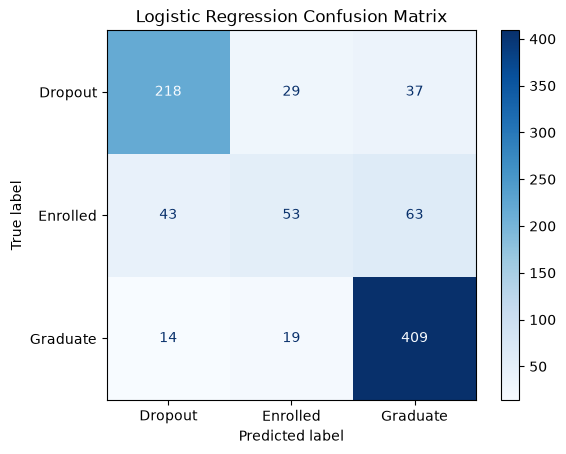

In [20]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compare the true test labels with Logistic Regression's predictions
logistic_cm = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=logistic_model.classes_
)

# Create a display that labels the rows and columns with target classes
logistic_display = ConfusionMatrixDisplay(
    confusion_matrix=logistic_cm,
    display_labels=logistic_model.classes_
)

# Draw the confusion matrix
logistic_display.plot(cmap="Blues", values_format="d")

# Add a title to identify the model
plt.title("Logistic Regression Confusion Matrix")

# Show the plot
plt.show()

Logistic Regression performed well for Graduate and Dropout students, but it struggled to identify Enrolled students, often confusing them with the other two classes.

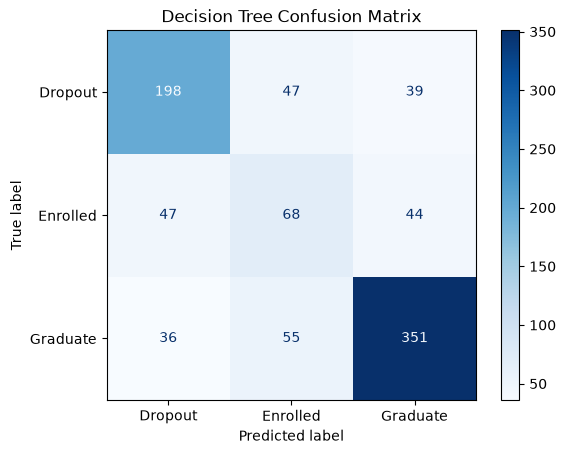

In [21]:
# Compare actual test labels with the Decision Tree predictions
tree_cm = confusion_matrix(
    y_test,
    tree_predictions,
    labels=tree_model.classes_
)

# Create a labeled display for the confusion matrix
tree_display = ConfusionMatrixDisplay(
    confusion_matrix=tree_cm,
    display_labels=tree_model.classes_
)

# Draw the matrix and format counts as whole numbers
tree_display.plot(cmap="Blues", values_format="d")

# Add a title naming the model
plt.title("Decision Tree Confusion Matrix")

# Show the plot
plt.show()

KNN OCnfusion Matrix

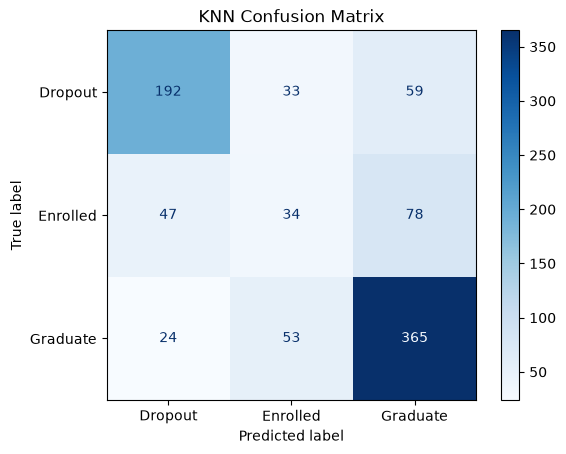

In [22]:
# Compare actual test labels with the KNN predictions
knn_cm = confusion_matrix(
    y_test,
    knn_predictions,
    labels=knn_model.classes_
)

# Create a labeled display for the confusion matrix
knn_display = ConfusionMatrixDisplay(
    confusion_matrix=knn_cm,
    display_labels=knn_model.classes_
)

# Draw the matrix and format counts as whole numbers
knn_display.plot(cmap="Blues", values_format="d")

# Add a title naming the model
plt.title("KNN Confusion Matrix")

# Show the plot
plt.show()

KNN correctly classified 192/284 Dropout cases (about 68%), 34/159 Enrolled cases (about 21%), and 365/442 Graduate cases (about 83%). It did best on Graduate students and struggled most with Enrolled students, often predicting them as Graduate.

Gaussian Naive Bayes confusion matrix

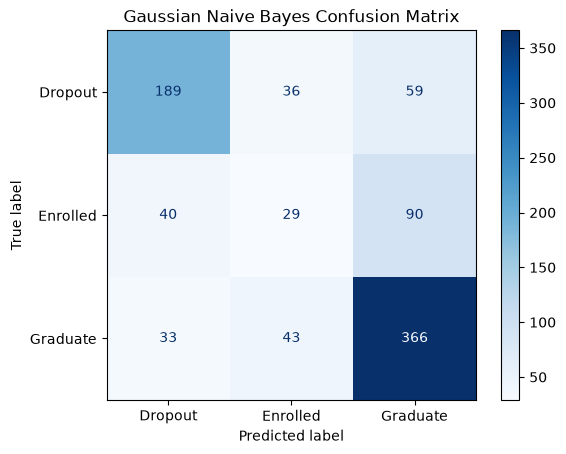

In [23]:
# Compare actual test labels with the Naive Bayes predictions
naive_bayes_cm = confusion_matrix(
    y_test,
    naive_bayes_predictions,
    labels=naive_bayes_model.classes_
)

# Create a labeled display for the confusion matrix
naive_bayes_display = ConfusionMatrixDisplay(
    confusion_matrix=naive_bayes_cm,
    display_labels=naive_bayes_model.classes_
)

# Draw the matrix and format counts as whole numbers
naive_bayes_display.plot(cmap="Blues", values_format="d")

# Add a title naming the model
plt.title("Gaussian Naive Bayes Confusion Matrix")

# Show the plot
plt.show()

Gaussian Naive Bayes correctly classified 189/284 Dropout cases (about 67%), 29/159 Enrolled cases (about 18%), and 366/442 Graduate cases (about 83%). It struggled most with Enrolled students: 90 of them were predicted as Graduate.

SVM confusion matrix

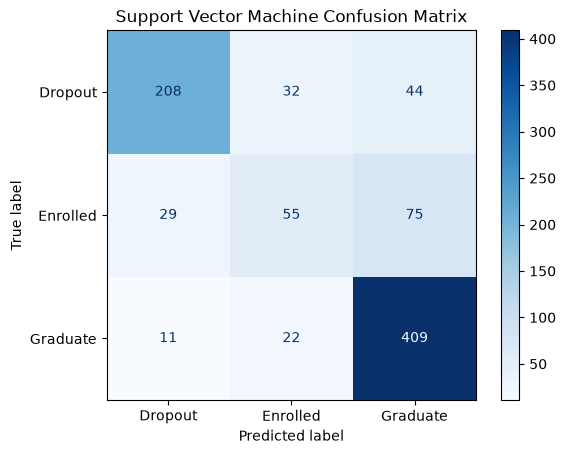

In [24]:
# Compare actual test labels with the SVM predictions
svm_cm = confusion_matrix(
    y_test,
    svm_predictions,
    labels=svm_model.classes_
)

# Create a labeled display for the confusion matrix
svm_display = ConfusionMatrixDisplay(
    confusion_matrix=svm_cm,
    display_labels=svm_model.classes_
)

# Draw the matrix and format counts as whole numbers
svm_display.plot(cmap="Blues", values_format="d")

# Add a title naming the model
plt.title("Support Vector Machine Confusion Matrix")

# Show the plot
plt.show()

SVM correctly classified 208/284 Dropout cases (about 73%), 55/159 Enrolled cases (about 35%), and 409/442 Graduate cases (about 93%). It handled Graduate cases as well as Logistic Regression and did slightly better on Enrolled cases, but Logistic Regression had the stronger overall metric scores.

identify the category-coded features

In [25]:
# List the columns whose integer values represent named categories
categorical_columns = [
    "Marital status",
    "Application mode",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

# Treat the remaining input columns as numeric or binary features
numeric_columns = [
    column for column in X.columns
    if column not in categorical_columns
]

# Check the number and names of columns in each group
print("Category-coded columns:", len(categorical_columns))
print(categorical_columns)

print("\nNumeric or binary columns:", len(numeric_columns))
print(numeric_columns)

Category-coded columns: 9
['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

Numeric or binary columns: 27
['Application order', 'Daytime/evening attendance\t', 'Previous qualification (grade)', 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemploy

build a preprocessing pipeline and rerun Logistic Regression first. One-hot encoding creates a separate indicator for each category; scaling puts numeric features on comparable ranges. Keeping preprocessing inside the pipeline ensures it learns from training data only.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Encode category codes as separate indicators and scale numeric features
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_columns
        ),
        (
            "numbers",
            StandardScaler(),
            numeric_columns
        )
    ]
)

# Combine preprocessing with the Logistic Regression classifier
logistic_encoded_model = make_pipeline(
    preprocessor,
    LogisticRegression(max_iter=1000, random_state=42)
)

# Fit preprocessing and the classifier using training data only
logistic_encoded_model.fit(X_train, y_train)

# Predict the target classes for the test data
logistic_encoded_predictions = logistic_encoded_model.predict(X_test)

# Calculate and display the test accuracy
logistic_encoded_accuracy = accuracy_score(
    y_test,
    logistic_encoded_predictions
)
print("Encoded Logistic Regression accuracy:", logistic_encoded_accuracy)

Encoded Logistic Regression accuracy: 0.7672316384180791


The encoded Logistic Regression accuracy is 0.767, almost the same as the baseline 0.768. One-hot encoding gives the category codes a more appropriate interpretation, even though accuracy barely changed.

Lets rerun the Decision Tree with the same preprocessing

In [27]:
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline

# Combine the preprocessing steps with a Decision Tree classifier
tree_encoded_model = make_pipeline(
    clone(preprocessor),
    DecisionTreeClassifier(random_state=42)
)

# Fit the preprocessing and tree using training data only
tree_encoded_model.fit(X_train, y_train)

# Predict the target classes for the test data
tree_encoded_predictions = tree_encoded_model.predict(X_test)

# Calculate and display the test accuracy
tree_encoded_accuracy = accuracy_score(
    y_test,
    tree_encoded_predictions
)
print("Encoded Decision Tree accuracy:", tree_encoded_accuracy)

Encoded Decision Tree accuracy: 0.6847457627118644


The encoded Decision Tree accuracy is 0.685, compared with 0.697 for its baseline. One-hot encoding changes how the tree can split the category-coded features, so the result changed.

In [28]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# Combine preprocessing with KNN using five neighboring examples
knn_encoded_model = make_pipeline(
    clone(preprocessor),
    KNeighborsClassifier(n_neighbors=5)
)

# Fit preprocessing and KNN using training data only
knn_encoded_model.fit(X_train, y_train)

# Predict the target classes for the test data
knn_encoded_predictions = knn_encoded_model.predict(X_test)

# Calculate and display the test accuracy
knn_encoded_accuracy = accuracy_score(
    y_test,
    knn_encoded_predictions
)
print("Encoded KNN accuracy:", knn_encoded_accuracy)

Encoded KNN accuracy: 0.7028248587570621


The encoded KNN accuracy is 0.703, up from its baseline 0.668. One-hot encoding changed the distance calculations, so KNN can compare those coded categories more meaningfully.

rerun Gaussian Naive Bayes with the same preprocessing

In [29]:
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# Combine preprocessing with the Gaussian Naive Bayes classifier
naive_bayes_encoded_model = make_pipeline(
    clone(preprocessor),
    GaussianNB()
)

# Fit preprocessing and Naive Bayes using training data only
naive_bayes_encoded_model.fit(X_train, y_train)

# Predict the target classes for the test data
naive_bayes_encoded_predictions = naive_bayes_encoded_model.predict(X_test)

# Calculate and display the test accuracy
naive_bayes_encoded_accuracy = accuracy_score(
    y_test,
    naive_bayes_encoded_predictions
)
print("Encoded Naive Bayes accuracy:", naive_bayes_encoded_accuracy)

Encoded Naive Bayes accuracy: 0.2440677966101695


The encoded Gaussian Naive Bayes accuracy is 0.244, much lower than its baseline 0.660. Gaussian Naive Bayes assumes each feature follows a Gaussian distribution within each class; one-hot indicator columns are binary, so this combination may not suit the model well. We’ll keep the result and compare its other metrics later.

rerun SVM with calibrated probabilities for AUC

In [30]:
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score

# Put preprocessing and the SVM together inside a pipeline
svm_base_pipeline = make_pipeline(
    clone(preprocessor),
    SVC(random_state=42)
)

# Calibrate the SVM so it can return class probabilities
svm_encoded_model = CalibratedClassifierCV(
    estimator=svm_base_pipeline,
    ensemble=False
)

# Fit the calibrated model using training data only
svm_encoded_model.fit(X_train, y_train)

# Predict the target classes for the test data
svm_encoded_predictions = svm_encoded_model.predict(X_test)

# Calculate and display the test accuracy
svm_encoded_accuracy = accuracy_score(
    y_test,
    svm_encoded_predictions
)
print("Encoded Support Vector Machine accuracy:", svm_encoded_accuracy)

Encoded Support Vector Machine accuracy: 0.7604519774011299


Encoded SVM accuracy is 0.760, close to its baseline 0.759. Now we’ll recalculate all six metrics for the updated models. This also lets us see whether Naive Bayes’s low accuracy is accompanied by low scores on the other metrics.

In [31]:
from sklearn.metrics import roc_auc_score

# Keep each updated model with its test predictions
encoded_models = {
    "Logistic Regression": logistic_encoded_model,
    "Decision Tree": tree_encoded_model,
    "KNN": knn_encoded_model,
    "Naive Bayes": naive_bayes_encoded_model,
    "Support Vector Machine": svm_encoded_model
}

encoded_predictions = {
    "Logistic Regression": logistic_encoded_predictions,
    "Decision Tree": tree_encoded_predictions,
    "KNN": knn_encoded_predictions,
    "Naive Bayes": naive_bayes_encoded_predictions,
    "Support Vector Machine": svm_encoded_predictions
}

# Store the recalculated metrics for each updated model
encoded_metric_rows = []

# Calculate all six metrics for each model
for model_name, model in encoded_models.items():
    predictions = encoded_predictions[model_name]
    probabilities = model.predict_proba(X_test)

    encoded_metric_rows.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(
            y_test,
            probabilities,
            multi_class="ovr",
            average="macro"
        ),
        "Precision": precision_score(
            y_test, predictions, average="macro"
        ),
        "Recall": recall_score(
            y_test, predictions, average="macro"
        ),
        "F1": f1_score(
            y_test, predictions, average="macro"
        ),
        "MCC": matthews_corrcoef(y_test, predictions)
    })

# Arrange the metric results in a table
encoded_results = pd.DataFrame(encoded_metric_rows)

# Display the updated comparison table without a row index
print(encoded_results.round(3).to_string(index=False))

         ML Model Name  Accuracy   AUC  Precision  Recall    F1   MCC
   Logistic Regression     0.767 0.881      0.712   0.685 0.693 0.614
         Decision Tree     0.685 0.731      0.619   0.622 0.620 0.492
                   KNN     0.703 0.798      0.632   0.613 0.618 0.505
           Naive Bayes     0.244 0.673      0.480   0.392 0.217 0.124
Support Vector Machine     0.760 0.855      0.709   0.673 0.684 0.602


In [33]:
from sklearn.metrics import classification_report

# Print the class-by-class results for each updated model
for model_name, model in encoded_models.items():

    # Get the predictions made by this model
    predictions = encoded_predictions[model_name]

    # Print the model name and its classification report
    print("\n", model_name)
    print(
        classification_report(
            y_test,
            predictions,
            labels=model.classes_,
            target_names=model.classes_,
            digits=3,
            zero_division=0
        )
    )


 Logistic Regression
              precision    recall  f1-score   support

     Dropout      0.783     0.750     0.766       284
    Enrolled      0.544     0.390     0.454       159
    Graduate      0.810     0.914     0.859       442

    accuracy                          0.767       885
   macro avg      0.712     0.685     0.693       885
weighted avg      0.753     0.767     0.756       885


 Decision Tree
              precision    recall  f1-score   support

     Dropout      0.693     0.708     0.700       284
    Enrolled      0.353     0.377     0.365       159
    Graduate      0.812     0.781     0.796       442

    accuracy                          0.685       885
   macro avg      0.619     0.622     0.620       885
weighted avg      0.691     0.685     0.688       885


 KNN
              precision    recall  f1-score   support

     Dropout      0.760     0.690     0.723       284
    Enrolled      0.390     0.289     0.332       159
    Graduate      0.747     0.8

The classification reports show that Logistic Regression leads overall, while all models still struggle to identify Enrolled students. Naive Bayes has an unusual result: it finds 96.2% of the Enrolled cases, but its precision for that class is only 19.7%, and it identifies just 1.4% of Graduates. That suggests it predicts Enrolled too often.

Before using that as the final Naive Bayes result, let’s try a model-specific preprocessing choice: Gaussian Naive Bayes doesn’t need numeric features scaled, so we’ll keep the one-hot categories but pass numeric values through unchanged. The current shared preprocessing may be a poor fit for this model.

In [34]:
# Encode category columns but leave numeric values on their original scales
naive_bayes_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore", sparse_output=False),
            categorical_columns
        ),
        (
            "numbers",
            "passthrough",
            numeric_columns
        )
    ]
)

# Combine this preprocessing with Gaussian Naive Bayes
naive_bayes_final_model = make_pipeline(
    naive_bayes_preprocessor,
    GaussianNB()
)

# Train the model on the training data
naive_bayes_final_model.fit(X_train, y_train)

# Predict classes for the test data
naive_bayes_final_predictions = naive_bayes_final_model.predict(X_test)

# Display accuracy and class-by-class performance
print(
    "Naive Bayes accuracy:",
    accuracy_score(y_test, naive_bayes_final_predictions)
)
print(
    classification_report(
        y_test,
        naive_bayes_final_predictions,
        labels=naive_bayes_final_model.classes_,
        target_names=naive_bayes_final_model.classes_,
        digits=3,
        zero_division=0
    )
)

Naive Bayes accuracy: 0.25536723163841807
              precision    recall  f1-score   support

     Dropout      0.581     0.239     0.339       284
    Enrolled      0.200     0.956     0.331       159
    Graduate      0.667     0.014     0.027       442

    accuracy                          0.255       885
   macro avg      0.483     0.403     0.232       885
weighted avg      0.555     0.255     0.182       885



In [35]:
# Get class probabilities from the final Naive Bayes model
naive_bayes_final_probabilities = naive_bayes_final_model.predict_proba(X_test)

# Calculate macro one-vs-rest AUC
naive_bayes_final_auc = roc_auc_score(
    y_test,
    naive_bayes_final_probabilities,
    multi_class="ovr",
    average="macro"
)

# Calculate Matthews correlation coefficient
naive_bayes_final_mcc = matthews_corrcoef(
    y_test,
    naive_bayes_final_predictions
)

# Display the two remaining metrics
print("Naive Bayes AUC:", naive_bayes_final_auc)
print("Naive Bayes MCC:", naive_bayes_final_mcc)

Naive Bayes AUC: 0.6834937840535424
Naive Bayes MCC: 0.13798471351036537


In [36]:
# Use the final Naive Bayes model and its predictions in the comparison
encoded_models["Naive Bayes"] = naive_bayes_final_model
encoded_predictions["Naive Bayes"] = naive_bayes_final_predictions

# Find the Naive Bayes row in the results table
naive_bayes_row = encoded_results["ML Model Name"] == "Naive Bayes"

# Update each metric using the final Naive Bayes predictions
encoded_results.loc[naive_bayes_row, "Accuracy"] = accuracy_score(
    y_test, naive_bayes_final_predictions
)
encoded_results.loc[naive_bayes_row, "AUC"] = naive_bayes_final_auc
encoded_results.loc[naive_bayes_row, "Precision"] = precision_score(
    y_test, naive_bayes_final_predictions, average="macro"
)
encoded_results.loc[naive_bayes_row, "Recall"] = recall_score(
    y_test, naive_bayes_final_predictions, average="macro"
)
encoded_results.loc[naive_bayes_row, "F1"] = f1_score(
    y_test, naive_bayes_final_predictions, average="macro"
)
encoded_results.loc[naive_bayes_row, "MCC"] = naive_bayes_final_mcc

# Display the final comparison table
print(encoded_results.round(3).to_string(index=False))

         ML Model Name  Accuracy   AUC  Precision  Recall    F1   MCC
   Logistic Regression     0.767 0.881      0.712   0.685 0.693 0.614
         Decision Tree     0.685 0.731      0.619   0.622 0.620 0.492
                   KNN     0.703 0.798      0.632   0.613 0.618 0.505
           Naive Bayes     0.255 0.683      0.483   0.403 0.232 0.138
Support Vector Machine     0.760 0.855      0.709   0.673 0.684 0.602


In [37]:
from pathlib import Path
import joblib

# Create a folder for the saved model files
model_folder = Path("model")
model_folder.mkdir(exist_ok=True)

# Save each final model pipeline
for model_name, model in encoded_models.items():
    file_name = model_name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, model_folder / file_name)

# Combine the test features and their true target labels
test_data = X_test.copy()
test_data["Target"] = y_test

# Save the test rows as a comma-separated CSV without row numbers
test_data.to_csv("test_data.csv", index=False)

# Check the files created for submission
print("Saved model files:", sorted(path.name for path in model_folder.iterdir()))
print("Test data shape:", test_data.shape)

Saved model files: ['decision_tree.joblib', 'knn.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib', 'support_vector_machine.joblib']
Test data shape: (885, 37)



##  Observations and Comparative Analysis

1. **Logistic Regression:** Achieved the highest accuracy (76.7%) and AUC (0.881), indicating the strongest overall classification performance among the five models.

2. **Support Vector Machine (SVM):** Achieved 76.0% accuracy and 0.855 AUC, performing closely to Logistic Regression.

3. **Decision Tree:** Achieved 68.5% accuracy. Its performance was lower than Logistic Regression and SVM.

4. **K-Nearest Neighbors (KNN):** Achieved 70.3% accuracy and 0.798 AUC, showing moderate classification performance.

5. **Naive Bayes:** Achieved 25.5% accuracy and 0.683 AUC. Its comparatively poor performance suggests that its distributional assumptions may not adequately represent this dataset.

### Overall Comparison

Logistic Regression performed best based on accuracy, AUC, F1-score and MCC. SVM was a close second. Therefore, Logistic Regression was selected as the best-performing model for this classification task.

The results also demonstrate that accuracy alone is insufficient for evaluating a multiclass classification problem. Precision, recall, F1-score, MCC, confusion matrices and classification reports provide additional insights into the models' performance across the three student outcome categories.


## Conclusion

Five machine-learning classification algorithms were implemented and evaluated using the Student Dropout and Academic Success dataset.

Among the five models, Logistic Regression achieved the highest accuracy of 76.7% and AUC of 0.881, making it the best-performing model overall. Support Vector Machine achieved the second-highest accuracy of 76.0%.

Decision Tree and K-Nearest Neighbors achieved moderate performance. Gaussian Naive Bayes showed comparatively poor performance on this dataset.

The results indicate that Logistic Regression is the most suitable model among the five evaluated algorithms for this classification task. The trained models were saved and integrated into a Streamlit application to enable evaluation of uploaded labelled datasets without retraining.